# Measure D

From `FINDINGS.md`:

> Changes to the ballot measure process. Yes 178,653, No 151,011. The yes share is 54.2 percent.
>
> Precinct shares run from 43.5 percent to 51.5 percent to 67.1 percent. The split runs north to south. The correlation with easting is 0.02, and the correlation with latitude is 0.38. The north voted yes heavily. District 2 is 67.5 percent yes. Districts 6, 8, and 7 are 58.5, 58.3, and 57.4 percent. Four districts are under half: District 9 (the Mission, Bernal Heights, and Portola) is 44.4 percent, District 11 (the Excelsior, the Outer Mission, and Oceanview) is 47.8 percent, District 4 (the Sunset) is 48.8 percent, and District 5 (the Western Addition, Hayes Valley, the Haight, and the Tenderloin) is 49.3 percent. The spread from District 9 to District 2 is 23.1 points.
>
> The yes share rises with the non-Hispanic white share of the precinct (r = 0.59) and with the bachelor’s-degree share (r = 0.56). It is lower where the Hispanic share is higher (r = −0.53). Households at $150,000 or more move with the yes share as well (r = 0.47).

Every number below is computed from the files in `source/`. Run the setup cell first, then the rest in order (Runtime → Run all). The last cell lists each number the memo section quotes next to the value computed here, and stops with an error if any differ.

In [1]:
# Run this cell first. It finds the sf-2026-drive folder (on Google Drive in Colab, or on
# this computer) and loads the shared code in notebooks/sf2026.py.
import subprocess
import sys
from pathlib import Path

try:
    import geopandas  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "geopandas"], check=True)

FOLDER_NAME = "sf-2026-drive"


def is_root(path: Path) -> bool:
    return (path / "source" / "precinct_results.csv").exists() and (path / "notebooks" / "sf2026.py").exists()


def find_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if is_root(candidate):
            return candidate
    try:
        from google.colab import drive
    except ImportError:
        raise FileNotFoundError("Open this notebook from inside the sf-2026-drive folder.")
    drive.mount("/content/drive")
    bases = [Path("/content/drive/MyDrive"), Path("/content/drive/Shareddrives")]
    for base in bases:
        if is_root(base / FOLDER_NAME):
            return base / FOLDER_NAME
    for base in bases:
        if base.exists():
            for helper in base.rglob("sf2026.py"):
                if is_root(helper.parent.parent):
                    return helper.parent.parent
    raise FileNotFoundError(
        f"Could not find the {FOLDER_NAME} folder on Drive. If you renamed it, set FOLDER_NAME above."
    )


ROOT = find_root()
sys.path.insert(0, str(ROOT / "notebooks"))
import pandas as pd
import sf2026 as sf

pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
data = sf.load(ROOT)
check = sf.MemoCheck()
print(f"Using the {ROOT.name} folder: {len(data)} precincts")

Using the sf-2026-drive folder: 514 precincts


## Citywide result

In [2]:
city = sf.citywide(data, "measure_d__yes", "measure_d__no")
city

{'measure_d__yes': 178653,
 'measure_d__no': 151011,
 'share_pct': 54.192450495049506,
 'margin': 27642}

## Precinct and supervisor-district geography

In [3]:
share, votes = sf.two_way(data, "measure_d__yes", "measure_d__no")
enough = data["ballots"] >= sf.MIN_BALLOTS
districts = sf.by_district(data, "measure_d__yes", "measure_d__no")
print("Precinct range, 10th / 50th / 90th percentile:", [round(v, 1) for v in sf.percentile_range(share, enough)])
districts.round(1).to_frame("Yes share, percent")

Precinct range, 10th / 50th / 90th percentile: [np.float64(43.5), np.float64(51.5), np.float64(67.1)]


,"Yes share, percent"
Supervisorial,
1,53.30
2,67.50
3,56.20
4,48.80
5,49.30
6,58.50
7,57.40
8,58.30
9,44.40


In [4]:
check.number("Yes votes", 178653, city["measure_d__yes"], 0)
check.number("No votes", 151011, city["measure_d__no"], 0)
check.number("Yes share, percent", 54.2, city["share_pct"])
for name, memo, value in zip(["10th", "50th", "90th"], [43.5, 51.5, 67.1], sf.percentile_range(share, enough)):
    check.number(f"Precinct share, {name} percentile", memo, value)
geography = sf.geography_correlations(data, share, votes >= sf.MIN_BALLOTS)
check.number("Correlation with easting", 0.02, geography["east-west (easting)"], 2)
check.number("Correlation with latitude", 0.38, geography["north-south (latitude)"], 2)
check.number("Yes share, District 2", 67.5, districts[2])
check.number("Yes share, District 6", 58.5, districts[6])
check.number("Yes share, District 8", 58.3, districts[8])
check.number("Yes share, District 7", 57.4, districts[7])
check.number("Yes share, District 9", 44.4, districts[9])
check.number("Yes share, District 11", 47.8, districts[11])
check.number("Yes share, District 4", 48.8, districts[4])
check.number("Yes share, District 5", 49.3, districts[5])
under = sorted(districts.index[districts < 50])
check.fact("Districts under half", "4, 5, 9, 11", under, under == [4, 5, 9, 11])
check.fact("Highest and lowest district", "District 2 and District 9",
           f"District {districts.idxmax()} and District {districts.idxmin()}",
           (districts.idxmax(), districts.idxmin()) == (2, 9))
check.number("Spread from District 9 to District 2, points", 23.1, districts.max() - districts.min())
geography.to_frame()

,r
east-west (easting),0.02
north-south (latitude),0.38


## Neighborhoods in the districts the memo names

In [5]:
named = data[data["Supervisorial"].isin([4, 5, 9, 11])]
(named.groupby("Supervisorial")["Neighborhood"]
      .agg(lambda n: ", ".join(f"{k.title()} ({v})" for k, v in n.value_counts().items()))
      .to_frame("Neighborhoods (precincts)"))

,Neighborhoods (precincts)
Supervisorial,
4,Sunset/Parkside (47)
5,"Hayes Valley (11), Tenderloin (10), Western Ad..."
9,"Mission (22), Bernal Heights (15), Portola (8)..."
11,"Excelsior (17), Oceanview/Merced/Ingleside (15..."


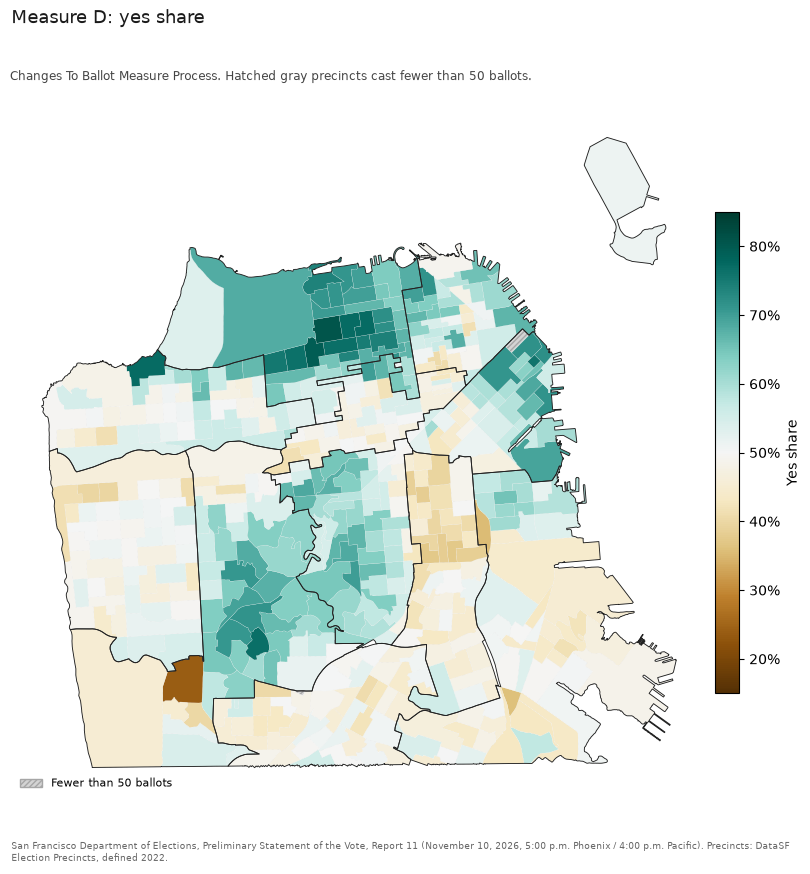

In [6]:
sf.rate_map(data, share, votes, "Measure D: yes share",
            "Changes To Ballot Measure Process. Hatched gray precincts cast fewer than 50 ballots.", "Yes share")

## Census comparison

In [7]:
r = sf.census_correlations(data, share, sf.census_frame(data))
display(r.to_frame())
check.number("Correlation with Non-Hispanic white", 0.59, r["Non-Hispanic white"], 2)
check.number("Correlation with Bachelor's degree or higher", 0.56, r["Bachelor's degree or higher"], 2)
check.number("Correlation with Hispanic", -0.53, r["Hispanic"], 2)
check.number("Correlation with Households at $150,000+", 0.47, r["Households at $150,000+"], 2)

,r
Non-Hispanic Asian,-0.26
Non-Hispanic white,0.59
Hispanic,-0.53
Bachelor's degree or higher,0.56
Renters,-0.05
"Households at $150,000+",0.47
Foreign born,-0.32


## Numbers the memo quotes

In [8]:
check.report();

,claim,memo,computed,matches
0,Yes votes,"178,653","178,653",yes
1,No votes,"151,011","151,011",yes
2,"Yes share, percent",54.2,54.2,yes
3,"Precinct share, 10th percentile",43.5,43.5,yes
4,"Precinct share, 50th percentile",51.5,51.5,yes
5,"Precinct share, 90th percentile",67.1,67.1,yes
6,Correlation with easting,0.02,0.02,yes
7,Correlation with latitude,0.38,0.38,yes
8,"Yes share, District 2",67.5,67.5,yes
9,"Yes share, District 6",58.5,58.5,yes


All 23 numbers checked match the memo.
